# 05. Where the time goes: batched bounding

The bounding step of branch and bound is the same computation on many boxes.
jaxglobal compiles it once with `jax.jit(jax.vmap(bound))` and calls it on a
whole batch of boxes at a time. This notebook measures what that buys, and
where the rest of the solver's time goes:

1. throughput of the compiled bounding kernel as a function of batch size;
2. the cost of compilation;
3. the split of a full `minimize` call into bounding, local solves and
   everything else.

All timings are on this machine's default JAX device:

In [1]:
import cProfile
import json
import os
import pathlib
import pstats
import sys
import time

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from jaxglobal import make_bounder, minimize
from jaxglobal.lp import make_constrained_bounder
from jaxglobal.problems import CONSTRAINED_PROBLEMS, PROBLEMS

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
P = {p.name: p for p in list(PROBLEMS) + list(CONSTRAINED_PROBLEMS)}
print(jax.devices())

[CpuDevice(id=0)]


## A cost model for a batched call

A call that bounds $k$ boxes costs a fixed overhead $t_0$ (dispatch from
Python, launching the compiled program, moving data) plus a per-box cost $c$:

$$ t(k) = t_0 + c\,k, \qquad \text{throughput}(k) = \frac{k}{t(k)} = \frac{1}{c + t_0/k} \;\longrightarrow\; \frac1c \quad (k\to\infty). $$

Bounding one box per call gives throughput $1/(t_0 + c)$; batching amortizes
$t_0$ until the per-box cost dominates, which happens around $k \approx t_0/c$.
We measure $t(k)$ for two problems: the 6-variable Hartmann function
(unconstrained, `make_bounder`), and the 9-variable Haverly pooling problem,
whose bounder also solves a small LP relaxation of the constraints per box
(`make_constrained_bounder`). Boxes are random sub-boxes of the domain;
compilation is timed separately and excluded from the call times.

In [2]:
def random_boxes(p, k, rng):
    a, b = np.sort(rng.uniform(p.lo, p.hi, (2, k, p.lo.size)), axis=0)
    return jnp.asarray(a), jnp.asarray(b)


def throughput(name, sizes=(1, 4, 16, 64, 256, 1024, 4096)):
    p = P[name]
    if hasattr(p, "ineq"):
        bound = jax.jit(jax.vmap(make_constrained_bounder(p.f, p.ineq, p.eq)))
    else:
        bound = jax.jit(jax.vmap(make_bounder(p.f)))
    rng = np.random.default_rng(0)
    out = {}
    for k in sizes:
        a, b = random_boxes(p, k, rng)
        t = time.perf_counter()
        jax.block_until_ready(bound(a, b))  # first call compiles for this batch shape
        tc = time.perf_counter() - t
        reps = max(3, int(2000 / k))
        t = time.perf_counter()
        for _ in range(reps):
            jax.block_until_ready(bound(a, b))
        dt = (time.perf_counter() - t) / reps
        out[k] = dict(boxes_per_s=k / dt, call_ms=1e3 * dt, compile_s=tc - dt)  # first call minus one execution
    return out


tp = {n: throughput(n) for n in ("hartmann6", "haverly")}
for n, d in tp.items():
    for k, v in d.items():
        print(f"{n:10s} batch {k:5d}: {v['boxes_per_s']:9.0f} boxes/s  {v['call_ms']:8.3f} ms/call  compile {v['compile_s']:.1f} s")

hartmann6  batch     1:     26738 boxes/s     0.037 ms/call  compile 0.2 s
hartmann6  batch     4:     55778 boxes/s     0.072 ms/call  compile 0.2 s
hartmann6  batch    16:    129195 boxes/s     0.124 ms/call  compile 0.2 s
hartmann6  batch    64:    177510 boxes/s     0.361 ms/call  compile 0.2 s
hartmann6  batch   256:    138500 boxes/s     1.848 ms/call  compile 0.2 s
hartmann6  batch  1024:    190531 boxes/s     5.374 ms/call  compile 0.2 s
hartmann6  batch  4096:    322518 boxes/s    12.700 ms/call  compile 0.2 s
haverly    batch     1:       379 boxes/s     2.637 ms/call  compile 0.9 s
haverly    batch     4:       542 boxes/s     7.379 ms/call  compile 0.7 s
haverly    batch    16:       562 boxes/s    28.470 ms/call  compile 0.7 s
haverly    batch    64:       610 boxes/s   104.950 ms/call  compile 0.7 s
haverly    batch   256:       704 boxes/s   363.579 ms/call  compile 0.8 s
haverly    batch  1024:       702 boxes/s  1459.422 ms/call  compile 0.7 s
haverly    batch  4096:  

Fitting $t(k) = t_0 + ck$ to the measured call times (least squares, weighted
by $1/t$ so the small batches count as much as the large ones):

hartmann6 : t0 = 0.039 ms, c = 4.33 µs/box, asymptotic throughput 1/c = 230,832 boxes/s, crossover t0/c = 9 boxes
haverly   : t0 = 1.212 ms, c = 1486.42 µs/box, asymptotic throughput 1/c = 673 boxes/s, crossover t0/c = 1 boxes


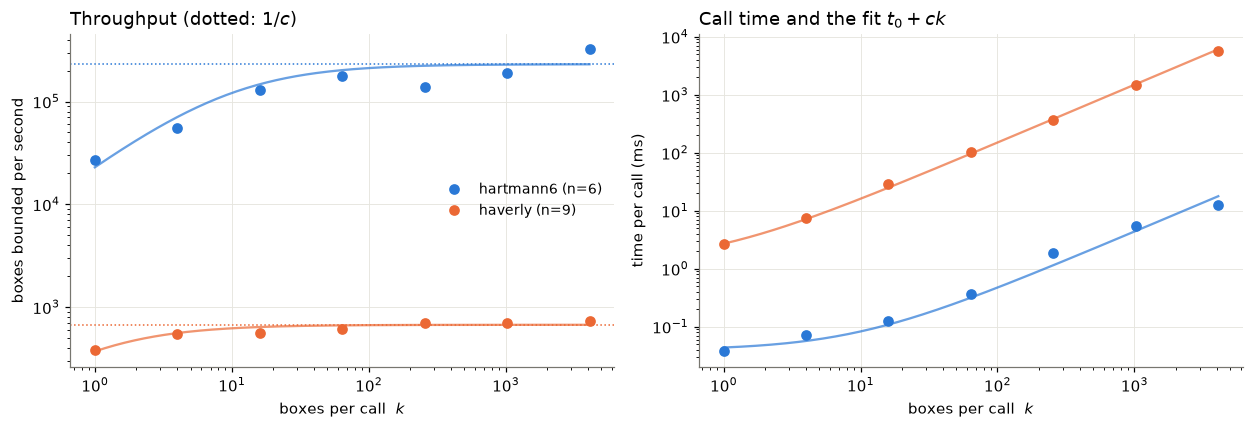

In [3]:
fits = {}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4))
for (n, d), col in zip(tp.items(), [BLUE, ORANGE]):
    k = np.array(list(d), dtype=float)
    t = np.array([v["call_ms"] for v in d.values()]) / 1e3
    A = np.c_[np.ones_like(k), k] / t[:, None]
    t0, c = np.linalg.lstsq(A, np.ones_like(k), rcond=None)[0]
    fits[n] = (t0, c)
    kk = np.geomspace(1, k.max(), 200)
    ax1.loglog(k, k / t, "o", color=col, ms=6, label=f"{n} (n={P[n].lo.size})")
    ax1.loglog(kk, kk / (t0 + c * kk), "-", color=col, lw=1.5, alpha=0.7)
    ax1.axhline(1 / c, color=col, ls=":", lw=1)
    ax2.loglog(k, 1e3 * t, "o", color=col, ms=6, label=n)
    ax2.loglog(kk, 1e3 * (t0 + c * kk), "-", color=col, lw=1.5, alpha=0.7)
    print(f"{n:10s}: t0 = {1e3 * t0:.3f} ms, c = {1e6 * c:.2f} µs/box, "
          f"asymptotic throughput 1/c = {1 / c:,.0f} boxes/s, crossover t0/c = {t0 / c:.0f} boxes")
ax1.set_xlabel("boxes per call  $k$"); ax1.set_ylabel("boxes bounded per second")
ax1.set_title("Throughput (dotted: $1/c$)", loc="left"); ax1.legend(frameon=False, fontsize=9)
ax2.set_xlabel("boxes per call  $k$"); ax2.set_ylabel("time per call (ms)")
ax2.set_title("Call time and the fit $t_0 + ck$", loc="left")
fig.tight_layout()

For Hartmann-6 the bounder is cheap: about 0.05 ms of fixed cost per call
and about 5 µs per box. Batching pays off accordingly. Throughput rises from
roughly 25,000 boxes/s at one box per call to 150,000–180,000 at 64 boxes, and
to over 300,000 at 4096, more than ten times the unbatched rate (exact figures
vary by 10–20% from run to run). The
straight-line model is only approximate: the measured rate dips at 256 boxes
and then rises past the fitted $1/c$, because the per-box cost itself depends
on the batch size (memory traffic, vectorization). The overall shape is as
predicted: overhead dominates for $k \lesssim t_0/c \approx 10$, and the
per-box cost dominates beyond that.

For Haverly the per-box cost is about 1.5 ms, some three hundred times larger,
because each box also solves an LP relaxation of the constraints. The fixed
cost is negligible next to that ($t_0/c \approx 1$), and batching gains only a
factor of two, from about 370 to about 720 boxes/s. The LP solve, not the
call overhead, sets the speed of constrained bounding on this CPU.

## Compilation

`jax.jit` compiles a new program for every input shape, so each batch size above
paid a compile once. That cost is independent of how many boxes are later
bounded with it:

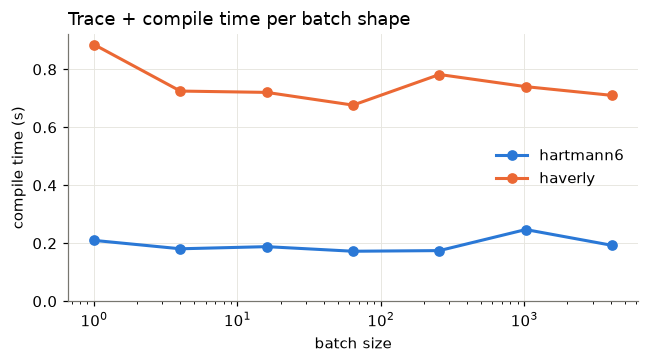

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for (n, d), col in zip(tp.items(), [BLUE, ORANGE]):
    ax.semilogx(list(d), [v["compile_s"] for v in d.values()], "o-", color=col, lw=2, label=n)
ax.set_xlabel("batch size"); ax.set_ylabel("compile time (s)")
ax.set_title("Trace + compile time per batch shape", loc="left"); ax.legend(frameon=False)
ax.set_ylim(bottom=0)
fig.tight_layout()

Compiling the bounder takes about 0.2 s for Hartmann-6 and about 0.8 s for
Haverly, roughly independent of the batch size. It is paid once per shape and
then amortized over every later call with that shape.

These are only the bounding kernels. A full solve compiles more: bounders for
the different batch shapes it uses, bound tightening, and the derivatives the
local solver needs. That is why the cold solves below take several seconds.

## Where a full solve spends its time

Bounding is only one part of `minimize`. Each iteration also runs a local NLP
solver from promising points to improve the incumbent, and does host-side
bookkeeping: selecting boxes, splitting, pruning and bound tightening. On the
first call for a function there is also compilation. To separate it, each
problem is solved twice with the same function object: the first (cold) call
compiles, the second (warm) call reuses the compiled kernels. The warm call is
profiled, attributing time to the bounding kernel (`evaluate`), the local
solves (`local`) and the rest; compilation is the difference cold − warm.

In [5]:
def time_split(name):
    p = P[name]
    kw = dict(ineq=p.ineq, eq=p.eq) if hasattr(p, "ineq") else {}
    f = lambda x: p.f(x)  # fresh function object: nothing cached from earlier notebooks or cells
    t = time.perf_counter()
    minimize(f, p.lo, p.hi, **kw)
    cold = time.perf_counter() - t
    pr = cProfile.Profile()
    t = time.perf_counter()
    pr.enable()
    r = minimize(f, p.lo, p.hi, **kw)
    pr.disable()
    total = time.perf_counter() - t
    cum = {}
    for (fn, _, func), (_, _, _, ct, _) in pstats.Stats(pr).stats.items():
        if fn.endswith("bnb.py") and func in ("local", "evaluate"):
            cum[func] = cum.get(func, 0) + ct
    bnd, local = cum.get("evaluate", 0.0), cum.get("local", 0.0)
    return dict(cold=cold, compile=max(cold - total, 0.0), total=total, bounding=bnd, local=local,
                other=total - bnd - local, nodes=r.nodes, status=r.status)


split = {n: time_split(n) for n in ("eggholder", "hartmann6", "G04", "haverly", "reactor")}
for n, s in split.items():
    print(f"{n:10s} {s['status']:8s} {s['nodes']:5d} nodes  cold {s['cold']:6.2f} s = compile {s['compile']:6.2f} s + "
          f"warm {s['total']:5.2f} s (bounding {s['bounding']:5.2f}, local {s['local']:4.2f}, other {s['other']:4.2f})")

eggholder  optimal     47 nodes  cold   4.28 s = compile   4.26 s + warm  0.01 s (bounding  0.01, local 0.01, other 0.00)
hartmann6  optimal   1099 nodes  cold   4.35 s = compile   4.28 s + warm  0.07 s (bounding  0.06, local 0.00, other 0.01)
G04        optimal      7 nodes  cold  10.38 s = compile  10.32 s + warm  0.06 s (bounding  0.05, local 0.01, other 0.00)
haverly    optimal     43 nodes  cold   7.48 s = compile   7.06 s + warm  0.42 s (bounding  0.30, local 0.11, other 0.00)
reactor    optimal   1039 nodes  cold  17.91 s = compile  15.16 s + warm  2.75 s (bounding  2.33, local 0.41, other 0.01)


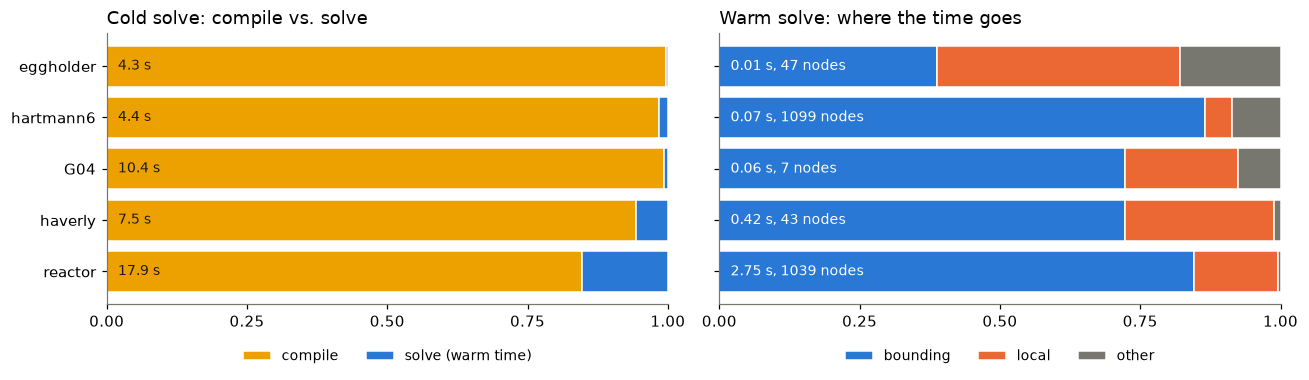

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
names = list(split)
for ax, parts, denom, title in [
    (ax1, [("compile", YELLOW), ("total", BLUE)], lambda n: split[n]["cold"], "Cold solve: compile vs. solve"),
    (ax2, [("bounding", BLUE), ("local", ORANGE), ("other", MUTED)], lambda n: split[n]["total"], "Warm solve: where the time goes"),
]:
    left = np.zeros(len(names))
    for part, col in parts:
        frac = np.array([split[n][part] / denom(n) for n in names])
        ax.barh(names, frac, left=left, color=col, edgecolor="white",
                label={"total": "solve (warm time)"}.get(part, part))
        left += frac
    ax.set_xlim(0, 1); ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0]); ax.grid(False)
    ax.set_title(title, loc="left"); ax.legend(ncol=len(parts), frameon=False, fontsize=9, loc="upper center",
                                               bbox_to_anchor=(0.5, -0.12))
for i, n in enumerate(names):
    ax1.text(0.02, i, f"{split[n]['cold']:.1f} s", va="center", fontsize=9, color=INK)
    ax2.text(0.02, i, f"{split[n]['total']:.2f} s, {split[n]['nodes']} nodes", va="center", fontsize=9, color="white")
ax1.invert_yaxis()
fig.tight_layout()

Compilation dominates every cold solve. It is 85% of the reactor network's
17.7 s and more than 94% for each of the other four problems. Once compiled,
the same solves take 0.02 to 2.6 s; Hartmann-6 works through about 1100
nodes in 0.07 s, roughly 16,000 nodes per second. In the warm solves (right),
bounding takes 70–85% of the time and the local solves most of the rest. The
exception is Eggholder, a 0.01 s solve of 47 nodes, where the local solves and
the fixed per-iteration bookkeeping weigh as much as the bounding.

So jaxglobal pays seconds of start-up per function and microseconds to
milliseconds per node. For the small test problems here, start-up is nearly
the whole cost. This is the gap to SCIP and BARON seen in notebook 04, and the
place where a faster solver would come from: compiling less, or reusing
compiled kernels across functions. The bounding itself is already batched and
gains little from further tuning on this machine.

In [7]:
json.dump(dict(throughput=tp, split=split), open(ROOT / "examples" / "throughput_results.json", "w"), indent=1)